## Importación de librerías

In [13]:
!pip install gurobipy pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.2 MB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 63.1 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.2/383.2 kB 36.3 MB/s eta 0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 53.9 MB/s eta 0:00:0031m67.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 52.3 MB/s eta 0:00:00m eta 0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 16.1 MB/s eta 0:00:00


In [2]:
import sys
import gurobipy as gp
from gurobipy import GRB
import time
import csv
import math
import random
import os
import pandas as pd

print('Python  :', sys.version.split()[0])
print('Gurobi  :', '.'.join(map(str, gp.gurobi.version())))

Python  : 3.14.4
Gurobi  : 13.0.3


# Contexto del problema
Una panadería distribuye diariamente pan fresco y varios productos elaborados a un conjunto fijo de minimarkets, almacenes y cafeterías de la ciudad. Cada local tiene un horario de apertura definido, por lo que las entregas deben realizarse dentro de una ventana de tiempo específica. Si el camión llega tarde, el local ya está atendiendo clientes y la recepción del producto se complica. La flota de reparto es limitada y cada ruta la hace siempre el mismo conductor, que ya conoce los accesos, a quién le entrega y las particularidades de cada cliente. Esta asignación entre el conductor y la ruta se mantiene durante todo el período de planificación.

## Suposiciones
* Cada cliente recibe exactamente una entrega por día.
* Los pedidos se conocen con anticipación.
* Los vehículos parten y regresan al mismo punto (la panadería).
* Las distancias entre clientes son simétricas y el tiempo de viaje es proporcional a la distancia recorrida.

---

# Notación

## Conjuntos e índices

| Símbolo | Descripción |
|---|---|
| $A$ | Conjunto de arcos válidos entre los nodos |
| $D$ | Conjunto de días del período de planificación |
| $R$ | Conjunto de rutas |
| $N_C = \{1,\dots,n\}$ | Conjunto de clientes |
| $N = \{0\} \cup N_C \cup \{n+1\}$ | Conjunto de nodos (clientes, depósito de salida (0) y retorno ($n+1$)) |
| $N_{TW} \subseteq N_C$ | Clientes con ventana de tiempo definida |

## Parámetros

| Símbolo | Descripción |
|---|---|
| $td_{ij}$ | Distancia de viaje entre nodos $i$ y $j$ |
| $tt_{ij}$ | Tiempo de viaje entre nodos $i$ y $j$ |
| $q_{it}$ | Cantidad demandada por el cliente $i$ en el día $t$ |
| $st_{it}$ | Tiempo de servicio en el cliente $i$ el día $t$ |
| $a_i$ | Inicio de la ventana de tiempo del cliente $i$ |
| $b_i$ | Fin de la ventana de tiempo del cliente $i$ |
| $a_W$ | Horario de apertura de la panadería |
| $b_W$ | Horario de cierre de la panadería |
| $Q$ | Capacidad máxima de carga de cada vehículo |
| $M$ | Constante suficientemente grande (Big-$M$) |

## Variables de decisión

| Símbolo | Descripción |
|---|---|
| $X^r_{ijt}$ | $1$ si la ruta $r$ recorre el arco $(i,j)$ en el día $t$; $0$ en otro caso |
| $Z^r_i$ | $1$ si el cliente $i$ es atendido por la ruta $r$; $0$ en otro caso |
| $W_{it}$ | Hora de llegada al cliente $i$ en el día $t$ |
| $dW^r$ | Hora de salida de la ruta $r$ desde la panadería |
| $rW^r_t$ | Hora de retorno de la ruta $r$ a la panadería en el día $t$ |

**Nota:** $Z^r_i$ y $dW^r$ no tienen índice de día. El cliente $i$ siempre es atendido por la misma ruta $r$, y cada ruta parte a la misma hora todos los días del período de planificación.

---

# Formulación matemática

## Función objetivo

$$ \min \sum_{(i,j,t) \in A} \sum_{r \in R} td_{ij} \cdot X^r_{ijt} \tag{1} $$

Se minimiza la distancia total recorrida por todos los vehículos durante el período de planificación.

## Restricciones

**Asignación única de cliente a ruta:**
$$ \sum_{r \in R} Z^r_i = 1 \qquad \forall\, i \in N_C \tag{2} $$
Cada local es atendido por exactamente un conductor durante todo el período de planificación.

**Conservación de flujo y grado:**
$$ \sum_{i \in N} X^r_{ijt} = Z^r_j \qquad \forall\, j \in N_C,\; r \in R,\; t \in D \tag{3} $$
$$ \sum_{j \in N} X^r_{ijt} = Z^r_i \qquad \forall\, i \in N_C,\; r \in R,\; t \in D \tag{4} $$
Si un cliente está asignado a una ruta, el camión debe llegar y salir de ese cliente exactamente una vez por día.

**Salida del depósito:**
$$ \sum_{j \in N} X^r_{0jt} = 1 \qquad \forall\, r \in R,\; t \in D \tag{5} $$
Cada camión sale de la panadería exactamente una vez por día.

**Seguimiento de tiempos con Big-$M$:**
$$ W_{it} + st_{it} + tt_{ij} \leq W_{jt} + M\bigl(1 - X^r_{ijt}\bigr) \qquad \forall\, i,j \in N,\; r \in R,\; t \in D \tag{7} $$
Si el camión va de $i$ a $j$, la hora de llegada a $j$ debe ser consistente con el tiempo de servicio en $i$ más el tiempo de viaje. Esta restricción también elimina subtours.

**Ventanas de tiempo:**
$$ a_i \leq W_{it} \leq b_i \qquad \forall\, i \in N_{TW},\; t \in D \tag{8} $$
El camión debe llegar a cada local dentro de su ventana de tiempo, antes de que el establecimiento abra a los clientes.

**Coordinación de horarios con el depósito:**
$$ dW^r + tt_{0j} \leq W_{jt} + M\bigl(1 - X^r_{0jt}\bigr) \qquad \forall\, j \in N_C,\; r \in R,\; t \in D \tag{9} $$
$$ W_{it} + st_{it} + tt_{i,n+1} \leq rW^r_t + M\bigl(1 - X^r_{i,n+1,t}\bigr) \qquad \forall\, i \in N_C,\; r \in R,\; t \in D \tag{10} $$
El primer cliente visitado determina la hora de salida desde la panadería. El último cliente determina la hora de regreso.

**Horario de operación de la panadería:**
$$ dW^r \geq a_W \qquad \forall\, r \in R \tag{11} $$
$$ rW^r_t \leq b_W \qquad \forall\, r \in R,\; t \in D \tag{12} $$
Los camiones no pueden salir antes de que abra la panadería ni regresar después de que cierre.

**Capacidad del vehículo:**
$$ \sum_{i \in N_C} q_{it} \cdot Z^r_i \leq Q \qquad \forall\, r \in R,\; t \in D \tag{14} $$
La carga total asignada a cada camión no puede superar su capacidad.

**Binariedad y no negatividad:**
$$ X^r_{ijt},\; Z^r_i \in \{0,1\};\qquad W_{it},\; dW^r,\; rW^r_t \geq 0 \tag{16} $$

---

# Restricciones omitidas

Las siguientes restricciones del modelo original de Campelo et al. (2019) quedan fuera del alcance de esta implementación:

* **(6) Períodos de despacho múltiples:** se asume un único período de despacho por día, por lo que no es necesario forzar que distintos períodos de un mismo cliente queden en rutas separadas.
* **(13) Fechas de liberación de pedidos ($rd_i$):** la demanda es determinista y los pedidos se conocen con anticipación, por lo que no existe una restricción de disponibilidad de carga en el depósito.
* **(15) Duración máxima de ruta:** se omite por simplificación. Las restricciones (11) y (12) sobre el horario de operación de la panadería acotan implícitamente la duración de cada ruta.

### 1. Generación de Datos

In [3]:
# ==========================================
# 1. FUNCIÓN GENERADORA (CALIBRADA Y NO TRIVIAL)
# ==========================================
def generar_instancia_desde_cvrplib(nombre_instancia, datos_clientes, n_clientes=15, tipo_estres="capacidad"):
    N_C = list(range(1, n_clientes + 1))
    n_plus_1 = n_clientes + 1
    N = list(range(n_clientes + 2))
    D = [1, 2, 3]
    R = [1, 2, 3]

    coord_dep = (datos_clientes[0]['x'], datos_clientes[0]['y'])
    coordenadas = {0: coord_dep, n_plus_1: coord_dep}
    for i in N_C:
        coordenadas[i] = (datos_clientes[i]['x'], datos_clientes[i]['y'])

    A = [(i, j) for i in N for j in N if i != j and j != 0 and i != n_plus_1]

    td, tt = {}, {}
    for (i, j) in A:
        dist = math.sqrt((coordenadas[i][0] - coordenadas[j][0])**2 + (coordenadas[i][1] - coordenadas[j][1])**2)
        td[i, j] = round(dist, 2)
        tt[i, j] = round(dist, 2)

    q, st, a, b = {}, {}, {}, {}
    N_TW = []
    var_dia = {1: 1.0, 2: 1.15, 3: 0.90} # Fluctuación semanal

    for i in N_C:
        demanda_base = datos_clientes[i]['demanda']
        for t in D:
            q[i, t] = math.ceil(demanda_base * var_dia[t])
            st[i, t] = 10.0

        tw_inicio = datos_clientes[i]['inicio_tw']
        tw_fin = datos_clientes[i]['fin_tw']
        a[i] = tw_inicio
        b[i] = tw_inicio + max(30, (tw_fin - tw_inicio) * 0.35) if tipo_estres == "tiempo" else tw_fin
        N_TW.append(i)

    # 88% de ocupación para forzar Branch & Bound
    demanda_max_dia = max(sum(q[i, t] for i in N_C) for t in D)
    factor_apriete = 0.88 if tipo_estres == "capacidad" else 0.75
    Q = math.ceil((demanda_max_dia / len(R)) / factor_apriete)

    return {
        'nombre': nombre_instancia, 'A': A, 'N_C': N_C, 'N': N, 'N_TW': N_TW, 'R': R, 'D': D,
        'td': td, 'tt': tt, 'q': q, 'st': st, 'a': a, 'b': b,
        'a_W': datos_clientes[0]['inicio_tw'], 'b_W': datos_clientes[0]['fin_tw'],
        'Q': Q, 'M': 3000.0
    }

# ==========================================
# 2. BANCO DE INSTANCIAS (SOLOMON C101 Y R101)
# ==========================================
datos_solomon_c101 = [
    {'x': 40, 'y': 50, 'demanda': 0, 'inicio_tw': 0, 'fin_tw': 1236},
    {'x': 45, 'y': 68, 'demanda': 10, 'inicio_tw': 100, 'fin_tw': 250},
    {'x': 45, 'y': 70, 'demanda': 25, 'inicio_tw': 150, 'fin_tw': 300},
    {'x': 42, 'y': 66, 'demanda': 15, 'inicio_tw': 65,  'fin_tw': 180},
    {'x': 42, 'y': 68, 'demanda': 12, 'inicio_tw': 200, 'fin_tw': 350},
    {'x': 42, 'y': 65, 'demanda': 18, 'inicio_tw': 45,  'fin_tw': 150},
    {'x': 40, 'y': 69, 'demanda': 20, 'inicio_tw': 250, 'fin_tw': 400},
    {'x': 40, 'y': 66, 'demanda': 15, 'inicio_tw': 120, 'fin_tw': 240},
    {'x': 38, 'y': 68, 'demanda': 22, 'inicio_tw': 180, 'fin_tw': 320},
    {'x': 38, 'y': 70, 'demanda': 10, 'inicio_tw': 300, 'fin_tw': 450},
    {'x': 35, 'y': 66, 'demanda': 14, 'inicio_tw': 80,  'fin_tw': 200},
    {'x': 35, 'y': 69, 'demanda': 16, 'inicio_tw': 220, 'fin_tw': 360},
    {'x': 25, 'y': 85, 'demanda': 20, 'inicio_tw': 350, 'fin_tw': 500},
    {'x': 22, 'y': 75, 'demanda': 28, 'inicio_tw': 50,  'fin_tw': 160},
    {'x': 22, 'y': 85, 'demanda': 12, 'inicio_tw': 280, 'fin_tw': 420},
    {'x': 20, 'y': 80, 'demanda': 35, 'inicio_tw': 150, 'fin_tw': 280}
]

datos_solomon_r101 = [
    {'x': 35, 'y': 35, 'demanda': 0, 'inicio_tw': 0, 'fin_tw': 1000},
    {'x': 41, 'y': 49, 'demanda': 15, 'inicio_tw': 80,  'fin_tw': 180},
    {'x': 35, 'y': 17, 'demanda': 18, 'inicio_tw': 40,  'fin_tw': 120},
    {'x': 55, 'y': 45, 'demanda': 22, 'inicio_tw': 120, 'fin_tw': 220},
    {'x': 55, 'y': 20, 'demanda': 10, 'inicio_tw': 60,  'fin_tw': 150},
    {'x': 15, 'y': 30, 'demanda': 12, 'inicio_tw': 30,  'fin_tw': 110},
    {'x': 25, 'y': 30, 'demanda': 16, 'inicio_tw': 90,  'fin_tw': 200},
    {'x': 20, 'y': 50, 'demanda': 20, 'inicio_tw': 150, 'fin_tw': 260},
    {'x': 10, 'y': 40, 'demanda': 14, 'inicio_tw': 110, 'fin_tw': 210},
    {'x': 55, 'y': 60, 'demanda': 12, 'inicio_tw': 200, 'fin_tw': 310},
    {'x': 30, 'y': 60, 'demanda': 15, 'inicio_tw': 140, 'fin_tw': 240},
    {'x': 20, 'y': 65, 'demanda': 18, 'inicio_tw': 180, 'fin_tw': 290},
    {'x': 50, 'y': 35, 'demanda': 25, 'inicio_tw': 70,  'fin_tw': 160},
    {'x': 30, 'y': 25, 'demanda': 10, 'inicio_tw': 40,  'fin_tw': 130},
    {'x': 15, 'y': 10, 'demanda': 20, 'inicio_tw': 60,  'fin_tw': 150},
    {'x': 60, 'y': 15, 'demanda': 14, 'inicio_tw': 100, 'fin_tw': 200}
]

banco_instancias = {
    "Instancia1_Clustered": {"datos": datos_solomon_c101, "n_clientes": 15},
    "Instancia2_Dispersa": {"datos": datos_solomon_r101, "n_clientes": 15}
}
print("Datos y banco de instancias listos para el bucle.")

Datos y banco de instancias listos para el bucle.


### 2. Definición del Framework Matemático

In [4]:
class ConsistentVRPFramework:
    def __init__(self, data):
        self.data = data
        self.model = None
        self.X, self.Z, self.W, self.dW, self.rW = {}, {}, {}, {}, {}

    def build_model(self):
        self.model = gp.Model("CVRP_Consistent")
        N_C, N, N_TW, R, D = self.data['N_C'], self.data['N'], self.data['N_TW'], self.data['R'], self.data['D']
        td, tt, q, st = self.data['td'], self.data['tt'], self.data['q'], self.data['st']
        a, b, a_W, b_W, Q, M = self.data['a'], self.data['b'], self.data['a_W'], self.data['b_W'], self.data['Q'], self.data['M']
        A = self.data['A']

        self.X = self.model.addVars(A, D, R, vtype=GRB.BINARY, name="X")
        self.Z = self.model.addVars(N_C, R, vtype=GRB.BINARY, name="Z")
        self.W = self.model.addVars(N_C, D, vtype=GRB.CONTINUOUS, lb=0.0, name="W")
        self.dW = self.model.addVars(R, vtype=GRB.CONTINUOUS, lb=0.0, name="dW")
        self.rW = self.model.addVars(R, D, vtype=GRB.CONTINUOUS, lb=0.0, name="rW")

        self.model.setObjective(gp.quicksum(td[i, j] * self.X[i, j, t, r] for (i, j) in A for t in D for r in R), GRB.MINIMIZE)

        for i in N_C:
            self.model.addConstr(gp.quicksum(self.Z[i, r] for r in R) == 1, name=f"AsignacionUnica_{i}")

        for j in N_C:
            for r in R:
                for t in D:
                    self.model.addConstr(gp.quicksum(self.X[i, j, t, r] for i in N if (i, j) in A) == self.Z[j, r], name=f"FlujoEntrada_{j}_{r}_{t}")
        for i in N_C:
            for r in R:
                for t in D:
                    self.model.addConstr(gp.quicksum(self.X[i, j, t, r] for j in N if (i, j) in A) == self.Z[i, r], name=f"FlujoSalida_{i}_{r}_{t}")
        for r in R:
            for t in D:
                 self.model.addConstr(gp.quicksum(self.X[0, j, t, r] for j in N if (0, j) in A) == 1, name=f"SalidaDep_{r}_{t}")

        for r in R:
            for t in D:
                for i in N_C:
                    for j in N_C:
                        if i != j and (i, j) in A:
                            self.model.addConstr(self.W[i, t] + st[i, t] + tt[i, j] <= self.W[j, t] + M * (1 - self.X[i, j, t, r]), name=f"BigM_{i}_{j}_{r}_{t}")

        for i in N_TW:
            for t in D:
                self.model.addConstr(self.W[i, t] >= a[i], name=f"TW_Inicio_{i}_{t}")
                self.model.addConstr(self.W[i, t] <= b[i], name=f"TW_Fin_{i}_{t}")

        n_plus_1 = max(N)
        for j in N_C:
            for r in R:
                for t in D:
                    self.model.addConstr(self.dW[r] + tt[0, j] <= self.W[j, t] + M * (1 - self.X[0, j, t, r]), name=f"CoordSalida_{j}_{r}_{t}")
        for i in N_C:
            for r in R:
                for t in D:
                    self.model.addConstr(self.W[i, t] + st[i, t] + tt[i, n_plus_1] <= self.rW[r, t] + M * (1 - self.X[i, n_plus_1, t, r]), name=f"CoordRet_{i}_{r}_{t}")

        for r in R:
            self.model.addConstr(self.dW[r] >= a_W, name=f"Ap_Dep_{r}")
            for t in D:
                self.model.addConstr(self.rW[r, t] <= b_W, name=f"Ci_Dep_{r}_{t}")
                self.model.addConstr(gp.quicksum(q[i, t] * self.Z[i, r] for i in N_C) <= Q, name=f"Capacidad_{r}_{t}")

        self.model.update()

    def set_base_params(self):
        self.model.resetParams() # LIMPIEZA TOTAL PARA EVITAR EFECTO CASCADA
        self.model.setParam('Threads', 1)
        self.model.setParam('TimeLimit', 600)
        self.model.setParam('OutputFlag', 0)

    def run_relaxation(self):
        self.set_base_params()
        relaxed = self.model.relax()
        relaxed.optimize()
        return relaxed.ObjVal if relaxed.Status == GRB.OPTIMAL else None

    def run_configuration(self, config_name, params_dict):
        self.model.reset()
        self.set_base_params()
        for p, v in params_dict.items():
            self.model.setParam(p, v)

        start = time.time()
        self.model.optimize()
        t = time.time() - start

        if self.model.Status in [GRB.OPTIMAL, GRB.TIME_LIMIT] and self.model.SolCount > 0:
            return self.model.ObjVal, self.model.MIPGap * 100, t
        return None, None, t

    def run_tuning(self, tune_time_limit=300):
        print(" -> Ejecutando Gurobi Tuning...")
        self.model.reset()
        self.set_base_params()
        self.model.setParam('TuneTimeLimit', tune_time_limit)

        start = time.time()
        self.model.tune()

        if self.model.TuneResultCount > 0:
            self.model.getTuneResult(0)
            self.model.optimize()
            t = time.time() - start
            if self.model.SolCount > 0:
                return self.model.ObjVal, self.model.MIPGap * 100, t
        return None, None, time.time() - start

    def run_sensitivity_analysis(self, filename="sensibilidad.csv"):
      if self.model.SolCount == 0:
          print("    [!] No hay solución factible para análisis de sensibilidad.")
          return

      fixed_model = self.model.fixed()
      fixed_model.setParam('OutputFlag', 0)
      fixed_model.setParam('Method', 1)   # Dual Simplex
      fixed_model.setParam('Presolve', 0) # REQUERIDO para habilitar SARHSLow/SARHSUp
      fixed_model.optimize()

      if fixed_model.Status == GRB.OPTIMAL:
          with open(filename, mode='w', newline='', encoding='utf-8') as file:
              writer = csv.writer(file)
              writer.writerow(["Restriccion", "Precio_Sombra_Pi", "SARHSLow", "SARHSUp"])
              for r in self.data['R']:
                  for t in self.data['D']:
                      constr = fixed_model.getConstrByName(f"Capacidad_{r}_{t}")
                      if constr:
                          writer.writerow([f"Cap_{r}_{t}", f"{constr.Pi:.4f}", f"{constr.SARHSLow:.2f}", f"{constr.SARHSUp:.2f}"])
          print(f"    [OK] Sensibilidad guardada en {filename}")

    def exportar_resultados_csv(self, z_LP, res_milp, filename="resultados.csv"):
        with open(filename, mode='w', newline='', encoding='utf-8') as file:
            writer = csv.writer(file)
            writer.writerow(["Configuracion", "Valor_Objetivo", "Gap_%", "Tiempo_s", "Brecha_Integralidad_%"])

            # Validación explícita de z_LP para evitar errores de formato
            lp_str = f"{z_LP:.4f}" if z_LP is not None else "N/A"
            writer.writerow(["LP Relax", lp_str, "-", "-", "-"])

            z_MILP_base = res_milp.get("Baseline", (None, None, None))[0]

            for config, (obj, gap, run_time) in res_milp.items():
                # Validación estricta usando 'is not None' y previniendo división por cero
                if config == "Baseline" and z_LP is not None and z_MILP_base is not None and z_MILP_base != 0:
                    brecha = f"{((z_MILP_base - z_LP) / z_MILP_base * 100):.2f}"
                else:
                    brecha = "-"

                # Validación explícita para el resto de métricas
                obj_str = f"{obj:.4f}" if obj is not None else "N/A"
                gap_str = f"{gap:.2f}" if gap is not None else "-"

                writer.writerow([config, obj_str, gap_str, f"{run_time:.2f}", brecha])

### 3. Construcción y Ejecución de Experimentos

In [5]:
# ==========================================
# 3. BUCLE DE EXPERIMENTACIÓN AUTOMÁTICA
# ==========================================
tipos_de_estres = ["capacidad"]

for nombre_inst, info in banco_instancias.items():
    for estres in tipos_de_estres:
        sufijo_archivo = f"{nombre_inst}_{estres}"
        print(f"\n==============================================")
        print(f"PROCESANDO: {sufijo_archivo.upper()}")
        print(f"==============================================")

        try:
            # 1. Construir Instancia y Modelo
            data_instancia = generar_instancia_desde_cvrplib(
                nombre_instancia=sufijo_archivo,
                datos_clientes=info["datos"],
                n_clientes=info["n_clientes"],
                tipo_estres=estres
            )
            framework = ConsistentVRPFramework(data_instancia)
            framework.build_model()

            # 2. Relajación LP
            print(" -> Calculando LP Relax...")
            z_LP = framework.run_relaxation()
            print(f"    Valor LP: {z_LP:.2f}" if z_LP else "    Sin solución LP")

            # 3. Configuraciones MILP
            configs = {
                "Baseline": {},
                "No_Cuts": {'Cuts': 0},
                "No_Presolve": {'Presolve': 0},
                "MIPFocus_1": {'MIPFocus': 1},
                "MIPFocus_3": {'MIPFocus': 3},
                "No_Heuristics": {'Heuristics': 0}
            }

            resultados_milp = {}
            for nombre_config, params in configs.items():
                print(f" -> Corriendo MILP: {nombre_config}...")
                obj, gap, t = framework.run_configuration(nombre_config, params)
                resultados_milp[nombre_config] = (obj, gap, t)

            # 4. Gurobi Tuning
            obj_tune, gap_tune, t_tune = framework.run_tuning(tune_time_limit=300)
            resultados_milp["Tuning_Gurobi"] = (obj_tune, gap_tune, t_tune)

            # 5. Análisis de Sensibilidad (Se fuerza correr el Baseline limpio primero)
            print(" -> Preparando Análisis de Sensibilidad...")
            framework.run_configuration("Baseline", {'TimeLimit': 600})
            framework.run_sensitivity_analysis(f"sensibilidad_{sufijo_archivo}.csv")

            # 6. Guardar Resultados
            framework.exportar_resultados_csv(z_LP, resultados_milp, f"resultados_{sufijo_archivo}.csv")
            print(f"[¡OK!] Experimento {sufijo_archivo} completado y guardado con éxito.")

        except Exception as e:
            # Evita que un error mate el código durante la noche
            print(f"\n[ERROR CRÍTICO] Falló el procesamiento de {sufijo_archivo}.")
            print(f"Detalle técnico: {e}")
            print("Saltando automáticamente a la siguiente instancia...")

print("\n¡FIN DE TODOS LOS EXPERIMENTOS!")


PROCESANDO: INSTANCIA1_CLUSTERED_CAPACIDAD
Set parameter Username
Set parameter LicenseID to value 2874581
Academic license - for non-commercial use only - expires 2027-10-14
 -> Calculando LP Relax...
Reset all parameters
Set parameter Threads to value 1
Set parameter TimeLimit to value 600
    Valor LP: 121.50
 -> Corriendo MILP: Baseline...
Set parameter Threads to value 1
Set parameter TimeLimit to value 600
 -> Corriendo MILP: No_Cuts...
Set parameter Threads to value 1
Set parameter TimeLimit to value 600
 -> Corriendo MILP: No_Presolve...
Set parameter Threads to value 1
Set parameter TimeLimit to value 600
 -> Corriendo MILP: MIPFocus_1...
Set parameter Threads to value 1
Set parameter TimeLimit to value 600
 -> Corriendo MILP: MIPFocus_3...
Set parameter Threads to value 1
Set parameter TimeLimit to value 600
 -> Corriendo MILP: No_Heuristics...
Set parameter Threads to value 1
Set parameter TimeLimit to value 600
 -> Ejecutando Gurobi Tuning...
Set parameter Threads to value

### 4. Visualización de resultados

In [8]:
# ==========================================
# 4. VISUALIZACIÓN DE RESULTADOS
# ==========================================
# Cambia a "Instancia2_Dispersa_capacidad" para ver la otra
nombre_ver = "Instancia1_Clustered_capacidad"

print(f"--- Resultados: {nombre_ver} ---")
archivo_resultados = f"resultados_{nombre_ver}.csv"

if os.path.exists(archivo_resultados):
    display(pd.read_csv(archivo_resultados))
else:
    print(f"[!] No se encontró el archivo: {archivo_resultados}")

print(f"\n--- Sensibilidad: {nombre_ver} ---")
archivo_sensibilidad = f"sensibilidad_{nombre_ver}.csv"

if os.path.exists(archivo_sensibilidad):
    display(pd.read_csv(archivo_sensibilidad).head(10))
else:
    print(f"[!] No se generó el archivo de sensibilidad para {nombre_ver}.")

--- Resultados: Instancia1_Clustered_capacidad ---


,Configuracion,Valor_Objetivo,Gap_%,Tiempo_s,Brecha_Integralidad_%
0,LP Relax,121.50,-,-,-
1,Baseline,519.03,13.22,600.00,76.59
2,No_Cuts,519.03,23.40,600.00,-
3,No_Presolve,519.03,25.71,600.00,-
4,MIPFocus_1,519.03,20.72,600.00,-
5,MIPFocus_3,519.03,10.52,600.00,-
6,No_Heuristics,520.38,11.32,600.00,-
7,Tuning_Gurobi,NaN,-,600.19,-



--- Sensibilidad: Instancia1_Clustered_capacidad ---


,Restriccion,Precio_Sombra_Pi,SARHSLow,SARHSUp
0,Cap_1_1,0.0,95.0,inf
1,Cap_1_2,0.0,112.0,inf
2,Cap_1_3,0.0,88.0,inf
3,Cap_2_1,0.0,95.0,inf
4,Cap_2_2,0.0,111.0,inf
5,Cap_2_3,0.0,87.0,inf
6,Cap_3_1,0.0,82.0,inf
7,Cap_3_2,0.0,97.0,inf
8,Cap_3_3,0.0,75.0,inf


### 5.Analisis de los datos

#### Resultados de los experimentos

In [2]:
import pandas as pd

In [3]:
BASE_EXPERIMENTOS = r"resultados_experimentos/"

In [4]:
resultados_1 = pd.read_csv(BASE_EXPERIMENTOS + "resultados_Instancia1_Clustered_capacidad.csv")
resultados_2 = pd.read_csv(BASE_EXPERIMENTOS + "resultados_Instancia2_Dispersa_capacidad.csv")

In [5]:
resultados_1

,Configuracion,Valor_Objetivo,Gap_%,Tiempo_s,Brecha_Integralidad_%
0,LP Relax,121.50,-,-,-
1,Baseline,519.03,13.22,600.00,76.59
2,No_Cuts,519.03,23.40,600.00,-
3,No_Presolve,519.03,25.71,600.00,-
4,MIPFocus_1,519.03,20.72,600.00,-
5,MIPFocus_3,519.03,10.52,600.00,-
6,No_Heuristics,520.38,11.32,600.00,-
7,Tuning_Gurobi,NaN,-,600.19,-


In [6]:
resultados_2

,Configuracion,Valor_Objetivo,Gap_%,Tiempo_s,Brecha_Integralidad_%
0,LP Relax,571.29,-,-,-
1,Baseline,899.64,0.01,8.07,36.50
2,No_Cuts,899.64,0.00,27.96,-
3,No_Presolve,899.64,0.00,127.60,-
4,MIPFocus_1,899.64,0.00,11.38,-
5,MIPFocus_3,899.64,0.01,14.35,-
6,No_Heuristics,899.64,0.00,7.21,-
7,Tuning_Gurobi,899.64,0.01,293.66,-


#### Análisis de sensibilidad

In [29]:
sensibilidad_clustered = pd.read_csv(BASE_EXPERIMENTOS + "sensibilidad_Instancia1_Clustered_capacidad.csv")
sensibilidad_dispersa = pd.read_csv(BASE_EXPERIMENTOS + "sensibilidad_Instancia2_Dispersa_capacidad.csv")

In [30]:
sensibilidad_clustered

,Restriccion,Precio_Sombra_Pi,SARHSLow,SARHSUp
0,Cap_1_1,0.0,95.0,inf
1,Cap_1_2,0.0,112.0,inf
2,Cap_1_3,0.0,88.0,inf
3,Cap_2_1,0.0,95.0,inf
4,Cap_2_2,0.0,111.0,inf
5,Cap_2_3,0.0,87.0,inf
6,Cap_3_1,0.0,82.0,inf
7,Cap_3_2,0.0,97.0,inf
8,Cap_3_3,0.0,75.0,inf


In [31]:
sensibilidad_dispersa

,Restriccion,Precio_Sombra_Pi,SARHSLow,SARHSUp
0,Cap_1_1,0.0,86.0,inf
1,Cap_1_2,0.0,102.0,inf
2,Cap_1_3,0.0,79.0,inf
3,Cap_2_1,0.0,91.0,inf
4,Cap_2_2,0.0,107.0,inf
5,Cap_2_3,0.0,84.0,inf
6,Cap_3_1,0.0,64.0,inf
7,Cap_3_2,0.0,75.0,inf
8,Cap_3_3,0.0,59.0,inf


In [10]:
def resumen_relajacion(df, instancia):
    z_lp = df.loc[
        df["Configuracion"] == "LP Relax",
        "Valor_Objetivo"
    ].iloc[0]

    z_milp = df.loc[
        df["Configuracion"] == "Baseline",
        "Valor_Objetivo"
    ].iloc[0]

    brecha = (z_milp - z_lp) / z_milp * 100

    return {
        "Instancia": instancia,
        "z_LP": z_lp,
        "z_MILP": z_milp,
        "Brecha (%)": brecha
    }

tabla_relajacion = pd.DataFrame([
    resumen_relajacion(resultados_1, "Clustered"),
    resumen_relajacion(resultados_2, "Dispersa")
])

display(tabla_relajacion.round(2))

,Instancia,z_LP,z_MILP,Brecha (%)
0,Clustered,121.50,519.03,76.59
1,Dispersa,571.29,899.64,36.50


El valor de $z_{LP}$ corresponde al óptimo de la relajación lineal del problema, obtenida al permitir que las variables binarias tomen valores continuos en el intervalo $[0,1]$.

Dado que estamos minimizando, esta relajación amplía la región factible y su valor óptimo constituye una cota inferior válida del óptimo del problema entero.

Definimos la brecha de integralidad como:

$
\text{Brecha de integralidad}=
\frac{z_{MILP}-z_{LP}}{z_{MILP}}\times100\%
$

Para la instancia Clustered, se obtuvo una brecha del **76,59%**, lo que evidencia una diferencia considerable entre el valor de la relajación lineal y la mejor solución entera encontrada. Esto indica que la relajación proporciona una cota inferior poco ajustada respecto al incumbente.

La instancia dispersa muestra un resultado mucho más acotado entre z_LP y z_MILP.



In [11]:
import pandas as pd

def comparar_relajacion(df, instancia):
    z_lp = df.loc[
        df["Configuracion"] == "LP Relax",
        "Valor_Objetivo"
    ].iloc[0]

    # Excluir LP Relax y configuraciones sin solución
    datos = df[
        (df["Configuracion"] != "LP Relax") &
        (df["Valor_Objetivo"].notna())
    ].copy()

    datos["z_LP"] = z_lp
    datos["Brecha_Integralidad_Calculada_%"] = (
        (datos["Valor_Objetivo"] - z_lp)
        / datos["Valor_Objetivo"] * 100
    )

    datos.insert(0, "Instancia", instancia)

    return datos[[
        "Instancia",
        "Configuracion",
        "z_LP",
        "Valor_Objetivo",
        "Brecha_Integralidad_Calculada_%"
    ]].round(2)


tabla_comparacion = pd.concat([
    comparar_relajacion(resultados_1, "Clustered"),
    comparar_relajacion(resultados_2, "Dispersa")
], ignore_index=True)

display(tabla_comparacion)

,Instancia,Configuracion,z_LP,Valor_Objetivo,Brecha_Integralidad_Calculada_%
0,Clustered,Baseline,121.50,519.03,76.59
1,Clustered,No_Cuts,121.50,519.03,76.59
2,Clustered,No_Presolve,121.50,519.03,76.59
3,Clustered,MIPFocus_1,121.50,519.03,76.59
4,Clustered,MIPFocus_3,121.50,519.03,76.59
5,Clustered,No_Heuristics,121.50,520.38,76.65
6,Dispersa,Baseline,571.29,899.64,36.50
7,Dispersa,No_Cuts,571.29,899.64,36.50
8,Dispersa,No_Presolve,571.29,899.64,36.50
9,Dispersa,MIPFocus_1,571.29,899.64,36.50


Podemos observar que, dado que los valores de la función objetivo obtenidos por las distintas configuraciones son prácticamente iguales, las brechas de integralidad calculadas respecto a la relajación lineal también presentan variaciones mínimas.

Esto se debe a que todas las configuraciones comparten el mismo valor óptimo de la relajación lineal, por lo que las pequeñas diferencias en las brechas dependen únicamente de las variaciones en los incumbentes encontrados.

#### Análisis de GAP

Si bien en términos de brecha de integralidad se obtuvieron resultados muy similares, esto se debe principalmente a que los valores de la función objetivo encontrados por las distintas configuraciones son prácticamente iguales.

Para distinguir mejor el desempeño de cada configuración, resulta más informativo analizar el **GAP final**, ya que este refleja qué tan cerca quedó cada solución encontrada del óptimo, de acuerdo con la mejor cota inferior que logró demostrar Gurobi.

Recordemos que el GAP se define como:

$$
\text{GAP} = \frac{UB - LB}{UB}\times 100
$$

donde:

- $UB$ corresponde al mejor valor objetivo factible encontrado por el solver.
- $LB$ corresponde a la mejor cota inferior demostrada por Gurobi.

Por lo tanto, cuando dos configuraciones presentan el mismo valor objetivo pero distintos valores de GAP, esto indica que encontraron soluciones factibles de calidad similar, pero no lograron la misma calidad en la cota inferior. En particular, un GAP menor implica una cota inferior más ajustada y, en consecuencia, una mejor certificación de la calidad de la solución obtenida.

A continuación, se muestra un gráfico de barras con el GAP final de cada configuración para comparar su desempeño.

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# Orden fijo de las configuraciones
orden_configs = [
    "Baseline",
    "No_Cuts",
    "No_Presolve",
    "MIPFocus_1",
    "MIPFocus_3",
    "No_Heuristics"
]

def graficar_tiempo_y_gap(df, titulo_instancia):
    # Filtrar solo las configuraciones que queremos comparar
    datos = df[df["Configuracion"].isin(orden_configs)].copy()

    # Convertir columnas a numericas por si vienen como texto
    datos["Gap_%"] = pd.to_numeric(datos["Gap_%"], errors="coerce")
    datos["Tiempo_s"] = pd.to_numeric(datos["Tiempo_s"], errors="coerce")

    # Reordenar segun el orden definido
    datos = datos.set_index("Configuracion").loc[orden_configs].reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Subplot 1: Tiempo ---
    barras_tiempo = axes[0].bar(datos["Configuracion"], datos["Tiempo_s"])
    axes[0].set_title(f"Tiempo de resolución - {titulo_instancia}")
    axes[0].set_ylabel("Tiempo (s)")
    axes[0].tick_params(axis="x", rotation=30)

    for barra, valor in zip(barras_tiempo, datos["Tiempo_s"]):
        axes[0].text(
            barra.get_x() + barra.get_width()/2,
            barra.get_height() + max(datos["Tiempo_s"]) * 0.02,
            f"{valor:.2f}",
            ha="center"
        )

    # --- Subplot 2: GAP ---
    barras_gap = axes[1].bar(datos["Configuracion"], datos["Gap_%"])
    axes[1].set_title(f"GAP final - {titulo_instancia}")
    axes[1].set_ylabel("GAP (%)")
    axes[1].tick_params(axis="x", rotation=30)

    for barra, valor in zip(barras_gap, datos["Gap_%"]):
        axes[1].text(
            barra.get_x() + barra.get_width()/2,
            barra.get_height() + max(datos["Gap_%"]) * 0.02 if max(datos["Gap_%"]) > 0 else 0.01,
            f"{valor:.2f}%",
            ha="center"
        )

    plt.tight_layout()
    plt.show()

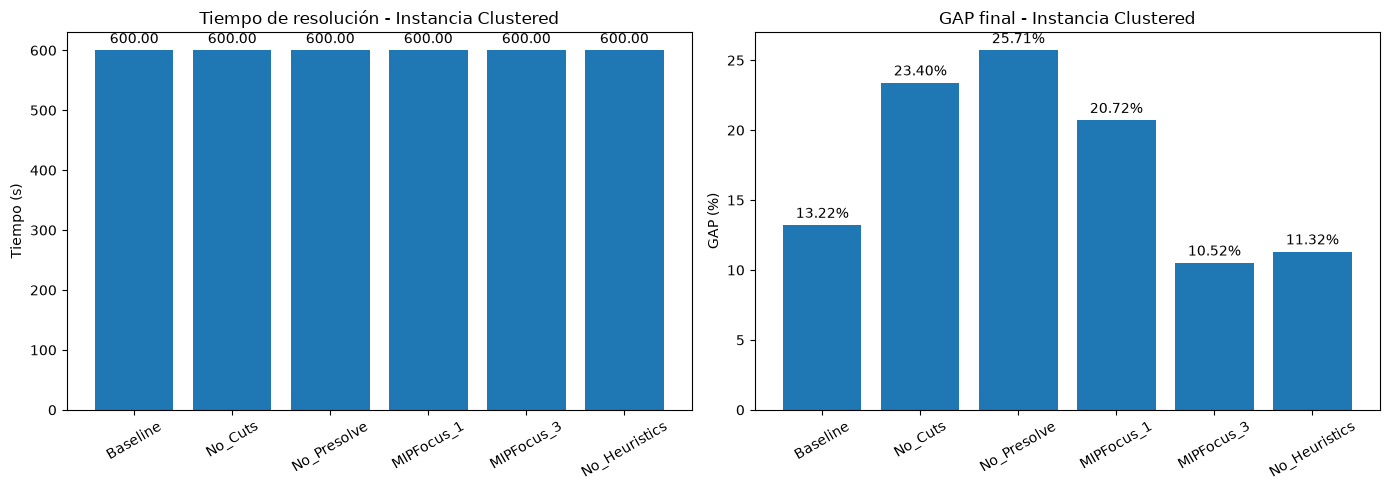

In [25]:
graficar_tiempo_y_gap(resultados_1, "Instancia Clustered")

Podemos observar que todas las configuraciones alcanzaron el límite de ejecución de 600 segundos sin conseguir cerrar completamente la brecha de optimalidad. Esto indica que, con un mayor tiempo de ejecución, el solver podría mejorar la solución encontrada, su cota inferior o ambas.

En estas condiciones, la configuración `MIPFocus=3` obtuvo el menor GAP final, con un **10,52%**, frente al **13,22%** del baseline. Dado que ambas configuraciones encontraron el mismo valor objetivo de **519,03**, podemos concluir que `MIPFocus=3` consiguió demostrar una cota inferior más ajustada, proporcionando una mayor garantía sobre la calidad de la solución.

Por otro lado, las configuraciones `Cuts=0` y `Presolve=0` presentaron GAPs de **23,40%** y **25,71%**, respectivamente, lo que evidencia una menor capacidad para cerrar la brecha de optimalidad dentro del mismo límite de tiempo.

Finalmente, aunque los valores objetivo encontrados son prácticamente idénticos, las cotas inferiores obtenidas por el solver son considerablemente superiores a la cota de **121,50** proporcionada por la relajación lineal inicial. Esto demuestra que el proceso de optimización permitió fortalecer las cotas del problema, aun cuando no logró certificar el óptimo entero.

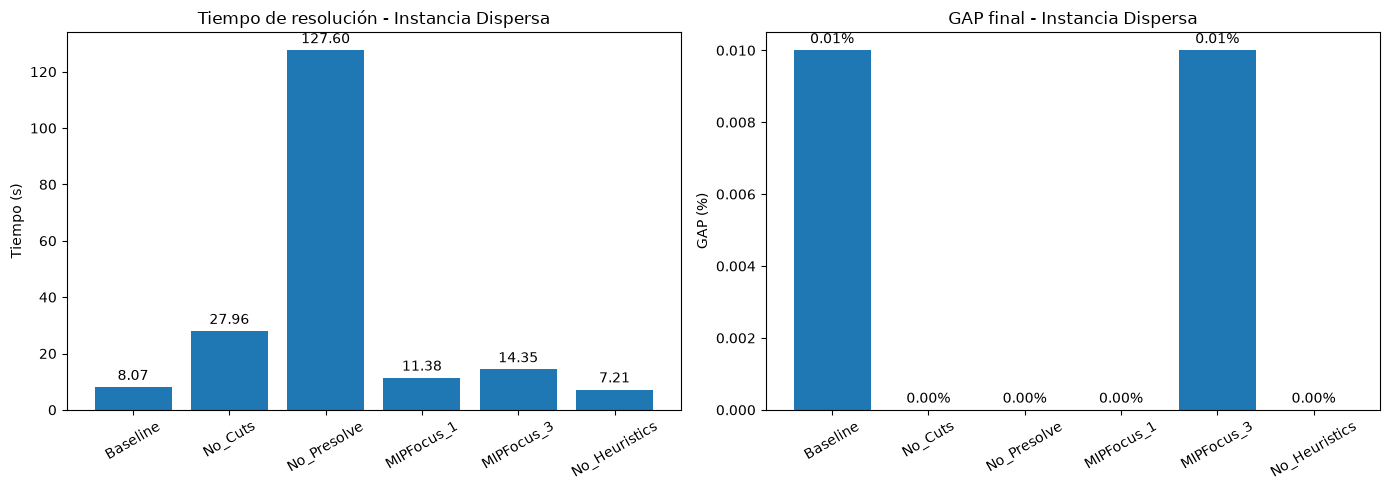

In [26]:
graficar_tiempo_y_gap(resultados_2, "Instancia Dispersa")

En la instancia Dispersa observamos un comportamiento diferente al de Clustered. Ninguna de las configuraciones alcanzó el límite de 600 segundos y todas obtuvieron GAPs finales prácticamente nulos, entre 0,00% y 0,01%. Esto indica que Gurobi logró cerrar casi completamente la brecha de optimalidad en un tiempo considerablemente menor al máximo permitido.

Dado que todas las configuraciones encontraron el mismo valor objetivo de 899,64, las principales diferencias se observan en los tiempos de resolución.

La configuración `No_Presolve` presentó el peor desempeño, con 127,60 segundos, aproximadamente 15,8 veces el tiempo del baseline (8,07 segundos). Por otro lado, `No_Cuts` fue la segunda más lenta, con 27,96 segundos.

Las configuraciones más rápidas fueron `No_Heuristics` (7,21 segundos) y el baseline (8,07 segundos), seguidas de `MIPFocus=1` (11,38 segundos) y `MIPFocus=3` (14,35 segundos).

Considerando conjuntamente ambas instancias, se observa que el desempeño de cada configuración depende de las características del problema. `MIPFocus=3` destacó por conseguir el menor GAP en Clustered, mientras que baseline y `No_Heuristics` presentaron tiempos competitivos en Dispersa.

Por tanto, estas tres configuraciones podrían considerarse candidatas para experimentos adicionales, aunque no es posible establecer una superioridad general a partir de únicamente dos instancias. Sería necesario realizar pruebas adicionales para evaluar la consistencia de sus resultados.

#### Análisis de sensibilidad
Los datos que tenemos son los siguientes:

In [ ]:
sensibilidad_clustered

,Restriccion,Precio_Sombra_Pi,SARHSLow,SARHSUp
0,Cap_1_1,0.0,95.0,inf
1,Cap_1_2,0.0,112.0,inf
2,Cap_1_3,0.0,88.0,inf
3,Cap_2_1,0.0,95.0,inf
4,Cap_2_2,0.0,111.0,inf
5,Cap_2_3,0.0,87.0,inf
6,Cap_3_1,0.0,82.0,inf
7,Cap_3_2,0.0,97.0,inf
8,Cap_3_3,0.0,75.0,inf


In [ ]:
sensibilidad_dispersa

,Restriccion,Precio_Sombra_Pi,SARHSLow,SARHSUp
0,Cap_1_1,0.0,86.0,inf
1,Cap_1_2,0.0,102.0,inf
2,Cap_1_3,0.0,79.0,inf
3,Cap_2_1,0.0,91.0,inf
4,Cap_2_2,0.0,107.0,inf
5,Cap_2_3,0.0,84.0,inf
6,Cap_3_1,0.0,64.0,inf
7,Cap_3_2,0.0,75.0,inf
8,Cap_3_3,0.0,59.0,inf


#### Análisis de los precios sombra

Primero, debemos entender que `Cap_n_m` identifica la restricción de capacidad del vehículo `n` durante el día `m`.

Podemos observar que el precio sombra es **0 en todas las restricciones analizadas**. Recordemos que el precio sombra representa la variación marginal del valor óptimo de la función objetivo ante un cambio en el lado derecho de una restricción:

$
\pi=\frac{\partial z^*}{\partial Q}
$

Donde:

- $z^*$ representa el valor óptimo de la función objetivo del modelo fijado.
- $Q$ representa la capacidad máxima del vehículo.

Este resultado se explica por el uso de `Model.fixed()`, que fija las variables enteras a los valores de una solución factible encontrada. En particular, las variables de asignación cliente-vehículo quedan determinadas, impidiendo que los clientes sean reasignados a otros vehículos.

La restricción de capacidad está definida como:

$
\sum_{i\in N_C}q_{it}Z_i^r\leq Q
$

Dado que las variables de asignación están fijadas, la demanda total asignada a cada vehículo permanece constante. Por tanto, aumentar la capacidad dentro del intervalo permisible no permite modificar la asignación ni mejorar el valor de la función objetivo del modelo fijado.

En consecuencia, la variación marginal del valor objetivo respecto a la capacidad es nula, lo que explica los precios sombra iguales a cero.

Es importante señalar que esta conclusión corresponde al modelo con las variables enteras fijadas y no necesariamente al problema MILP original, donde un aumento de capacidad podría permitir nuevas asignaciones y rutas.

In [32]:
tabla_sensibilidad = pd.DataFrame({
    "Resultado": [
        "Menor SARHSLow",
        "Mayor SARHSLow",
        "SARHSUp"
    ],
    "Clustered": [
        sensibilidad_clustered["SARHSLow"].min(),
        sensibilidad_clustered["SARHSLow"].max(),
        "∞ en todas"
    ],
    "Dispersa": [
        sensibilidad_dispersa["SARHSLow"].min(),
        sensibilidad_dispersa["SARHSLow"].max(),
        "∞ en todas"
    ]
})

display(tabla_sensibilidad)

,Resultado,Clustered,Dispersa
0,Menor SARHSLow,75.0,59.0
1,Mayor SARHSLow,112.0,107.0
2,SARHSUp,∞ en todas,∞ en todas


En este caso, `SARHSLow` y `SARHSUp` representan los límites inferior y superior del intervalo permisible para modificar el lado derecho de cada restricción de capacidad. Dentro de este intervalo se conserva la base óptima del modelo lineal fijado.

Podemos observar que, en todos los casos, el límite superior es infinito positivo, lo que indica que la capacidad puede aumentarse indefinidamente sin modificar la base óptima del modelo fijado.

Por otro lado, los límites inferiores varían entre ambas instancias, aunque presentan rangos relativamente similares. Estas diferencias pueden explicarse por las distintas demandas asignadas a cada vehículo durante los días de planificación.

### Conclusiones generales

Los experimentos muestran diferencias importantes en el desempeño computacional entre ambas instancias. Mientras que Clustered alcanzó el límite de 600 segundos sin certificar optimalidad, Dispersa obtuvo GAPs prácticamente nulos en tiempos considerablemente menores. Esto demuestra que una mayor distancia recorrida no implica necesariamente una mayor dificultad computacional.

Respecto a las configuraciones, `MIPFocus=3` obtuvo el menor GAP en Clustered, mejorando la cota inferior sin modificar el incumbente. Por otro lado, desactivar `Presolve` y `Cuts` perjudicó el desempeño, mientras que baseline y `No_Heuristics` presentaron los menores tiempos en Dispersa.

El análisis de sensibilidad mostró precios sombra nulos debido a que las variables enteras permanecieron fijadas, impidiendo modificar las asignaciones de clientes al aumentar la capacidad.

Finalmente, **no es posible determinar una configuración universalmente superior** con solo dos instancias. Sin embargo, los resultados evidencian que la elección de parámetros influye en el tiempo de resolución y en la capacidad del solver para certificar la calidad de las soluciones encontradas.